# YieldCraft AI

# Notebook 01 – AI Crop Recommendation System

## Module
Recommendation Engine – Crop Recommendation

## Domain
Agriculture | Machine Learning | Classification

## Project Description

The Crop Recommendation System is the first intelligent module of the YieldCraft AI platform. Its objective is to recommend the most suitable crops for cultivation based on soil nutrients and climatic conditions. The system analyses Nitrogen (N), Phosphorus (P), Potassium (K), temperature, humidity, soil pH, and rainfall to identify crops with the highest probability of successful cultivation.

Unlike conventional systems that recommend a single crop, this module is designed to return the Top-3 crop recommendations along with confidence scores. These recommendations will later be combined with Yield Prediction and Profit Recommendation modules to support comprehensive agricultural planning.

## Machine Learning Task

Multi-Class Classification

## Target Variable

Crop Label

## Input Features

- Nitrogen
- Phosphorus
- Potassium
- Temperature
- Humidity
- pH
- Rainfall

## Output

Top-3 Recommended Crops with Confidence Scores

# Section 2 — Import Libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.preprocessing import (
    LabelEncoder,
    StandardScaler
)

from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

# ============================================================
# Models
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# ============================================================
# Save Model
# ============================================================

import joblib

print("Libraries Loaded Successfully")

Libraries Loaded Successfully


# Section 3 — Load Dataset

In [2]:
DATA_PATH = "/kaggle/input/datasets/atharvaingle/crop-recommendation-dataset/Crop_recommendation.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


# Section 4 — Dataset Overview

In [3]:
print("="*60)
print("Dataset Information")
print("="*60)

display(df.head())

print("\nShape")
print(df.shape)

print("\nColumns")
print(df.columns.tolist())

print("\nData Types")
display(df.dtypes)

print("\nStatistical Summary")
display(df.describe().T)

Dataset Information


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice



Shape
(2200, 8)

Columns
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']

Data Types


N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label           object
dtype: object


Statistical Summary


,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.551818,36.917334,0.000000,21.000000,37.000000,84.250000,140.000000
P,2200.0,53.362727,32.985883,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.0,48.149091,50.647931,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,2200.0,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.0,71.481779,22.263812,14.258040,60.261953,80.473146,89.948771,99.981876
ph,2200.0,6.469480,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.0,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117


# Section 5 — Missing Values

In [4]:
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum()/len(df))*100
})

display(missing)

,Missing Values,Percentage
N,0,0.0
P,0,0.0
K,0,0.0
temperature,0,0.0
humidity,0,0.0
ph,0,0.0
rainfall,0,0.0
label,0,0.0


# Section 6 — Duplicate Values

In [5]:
duplicates = df.duplicated().sum()

print(f"Duplicate Records : {duplicates}")

Duplicate Records : 0


# Section 7 — Target Distribution

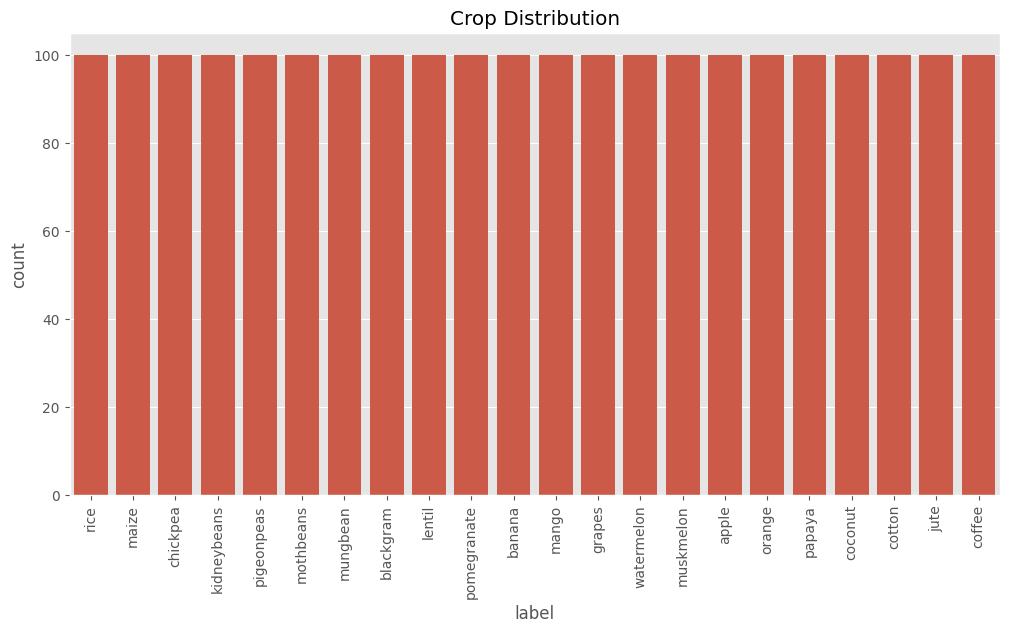

In [6]:
plt.figure(figsize=(12,6))

sns.countplot(
    data=df,
    x="label",
    order=df["label"].value_counts().index
)

plt.xticks(rotation=90)

plt.title("Crop Distribution")

plt.show()

# Section 8 — Feature Correlation

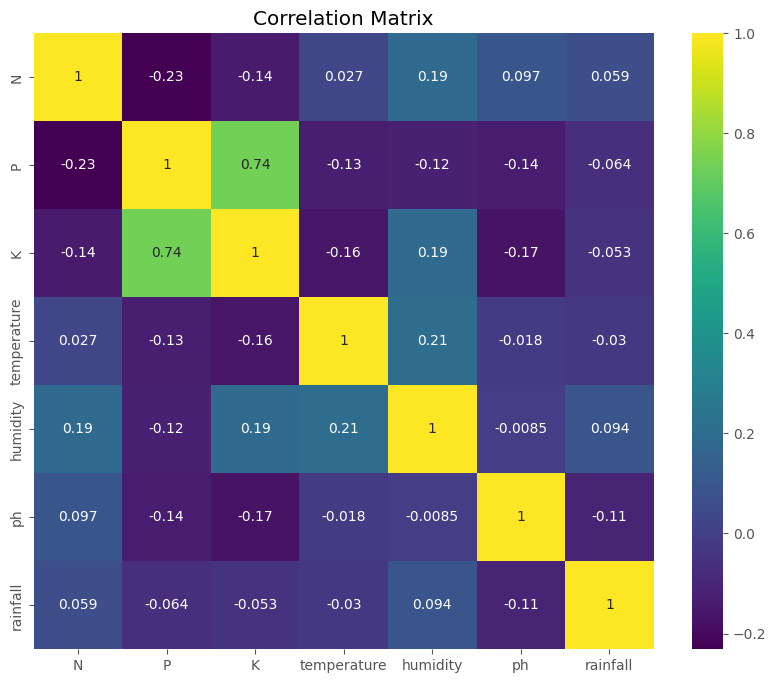

In [7]:
plt.figure(figsize=(10,8))

sns.heatmap(
    df.drop("label", axis=1).corr(),
    annot=True,
    cmap="viridis"
)

plt.title("Correlation Matrix")

plt.show()

# Section 9: Exploratory Data Analysis (EDA)

**9.1 Dataset Summary**

In [8]:
#print("="*60)
print("DATASET SUMMARY")
print("="*60)

print(f"Number of Samples : {df.shape[0]}")
print(f"Number of Features: {df.shape[1]-1}")
print(f"Target Variable   : label")
print(f"Number of Classes : {df['label'].nunique()}")

print("\nCrop Classes:\n")
print(sorted(df['label'].unique()))

DATASET SUMMARY
Number of Samples : 2200
Number of Features: 7
Target Variable   : label
Number of Classes : 22

Crop Classes:

['apple', 'banana', 'blackgram', 'chickpea', 'coconut', 'coffee', 'cotton', 'grapes', 'jute', 'kidneybeans', 'lentil', 'maize', 'mango', 'mothbeans', 'mungbean', 'muskmelon', 'orange', 'papaya', 'pigeonpeas', 'pomegranate', 'rice', 'watermelon']


**9.2 Feature Statistics**

In [9]:
display(df.describe().T.style.background_gradient(cmap="Blues"))

,count,mean,std,min,25%,50%,75%,max
N,2200.000000,50.551818,36.917334,0.000000,21.000000,37.000000,84.250000,140.000000
P,2200.000000,53.362727,32.985883,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.000000,48.149091,50.647931,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,2200.000000,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.000000,71.481779,22.263812,14.258040,60.261953,80.473146,89.948771,99.981876
ph,2200.000000,6.469480,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.000000,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117


**9.3 Data Types**

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


**9.4 Class Distribution**

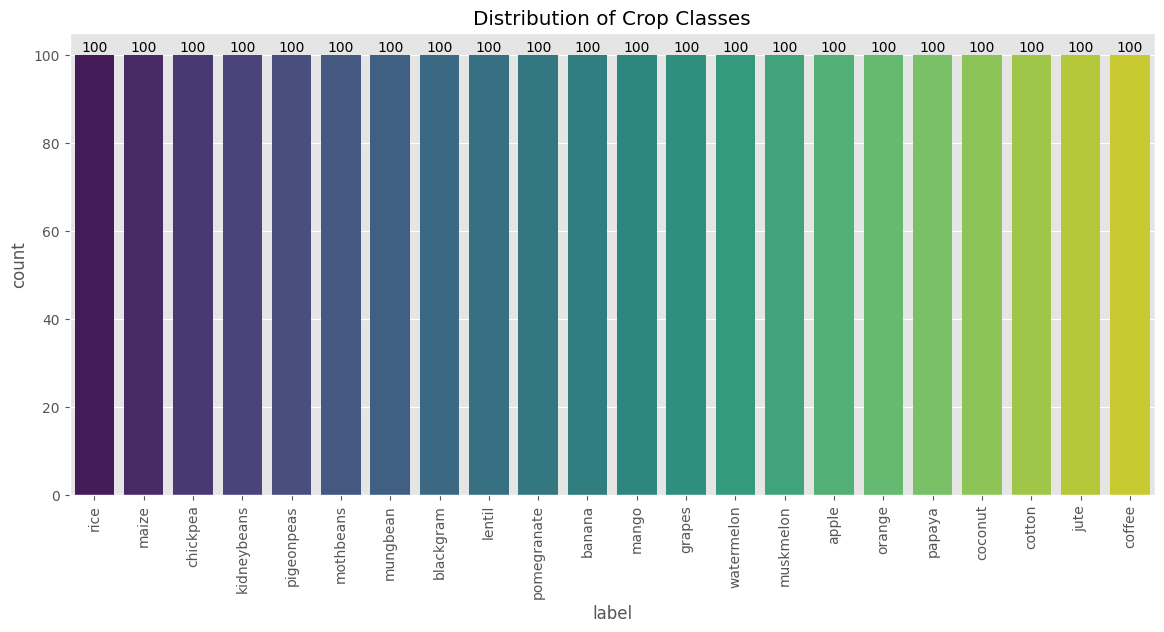

In [11]:
plt.figure(figsize=(14,6))

ax = sns.countplot(
    data=df,
    x="label",
    order=df['label'].value_counts().index,
    palette="viridis"
)

plt.xticks(rotation=90)

plt.title("Distribution of Crop Classes")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

**9.5 Histograms**

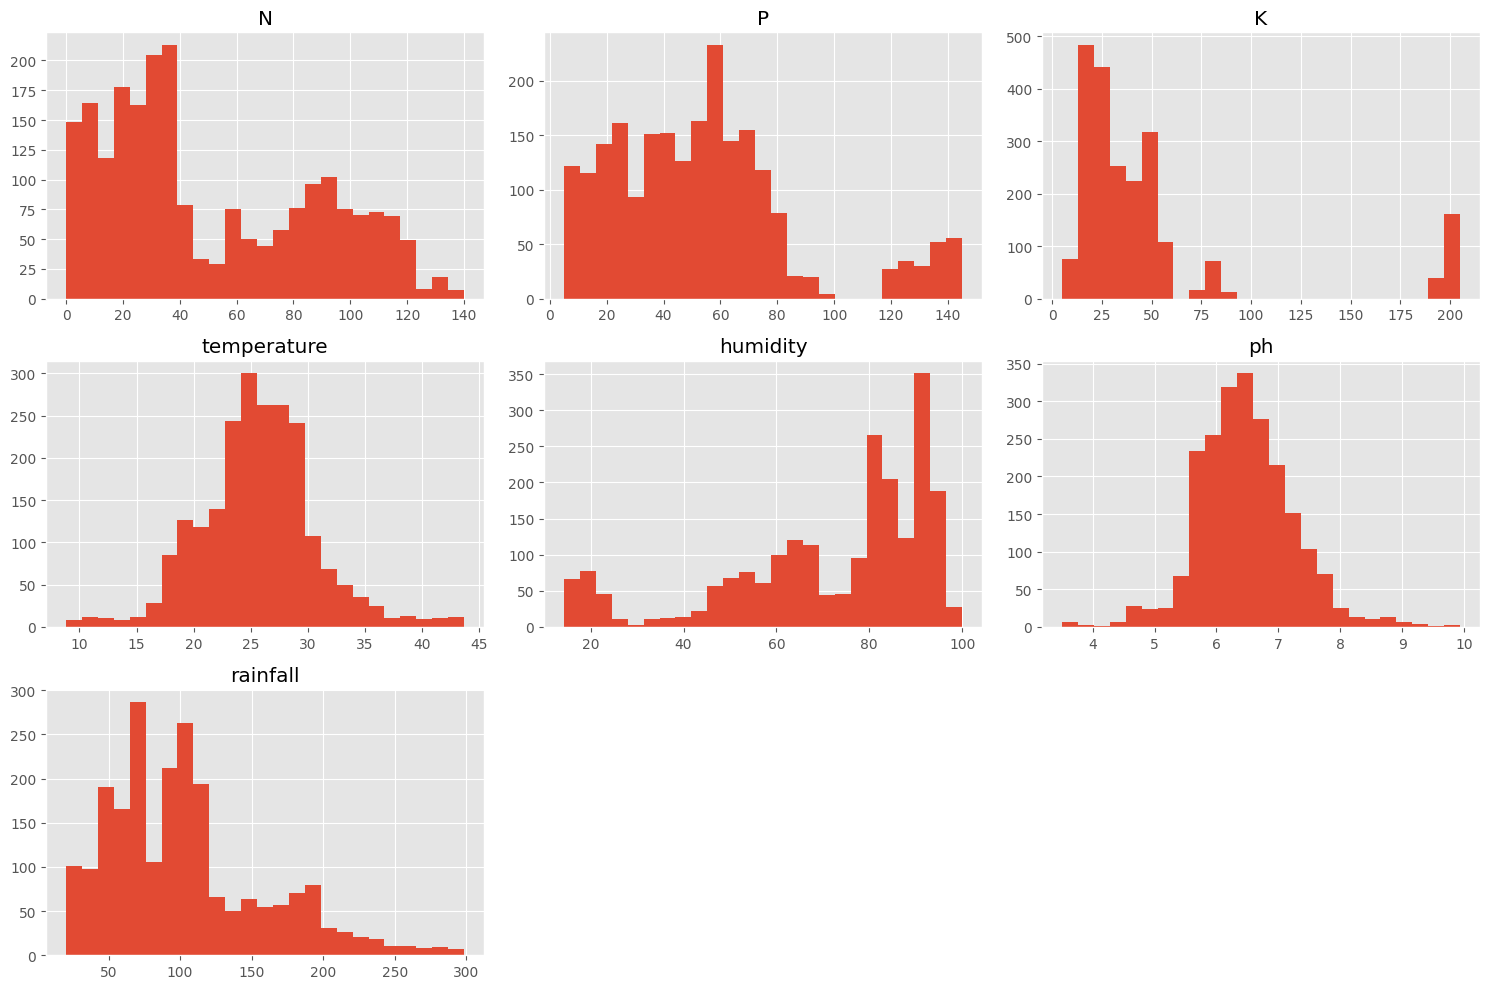

In [12]:
df.drop("label", axis=1).hist(
    figsize=(15,10),
    bins=25
)

plt.tight_layout()

plt.show()

**9.6 Box plots**

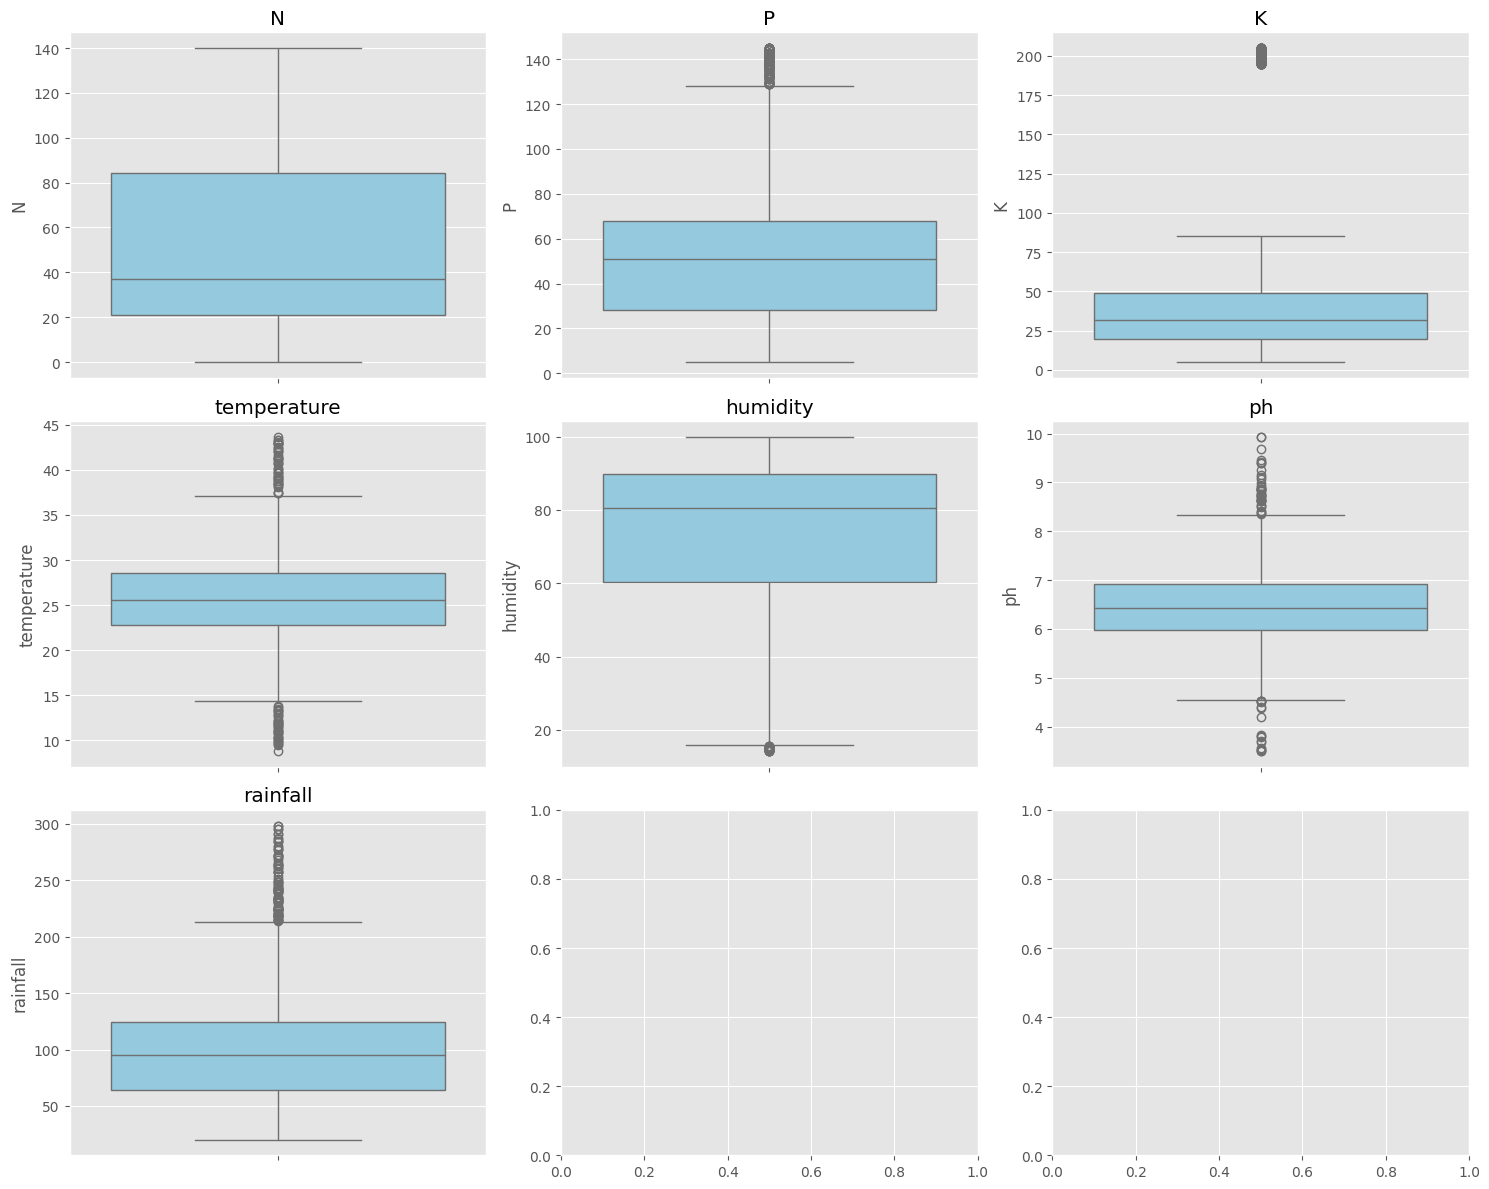

In [13]:
fig, axes = plt.subplots(3,3, figsize=(15,12))

axes = axes.flatten()

for i, col in enumerate(df.columns[:-1]):
    sns.boxplot(
        y=df[col],
        ax=axes[i],
        color="skyblue"
    )
    axes[i].set_title(col)

plt.tight_layout()

plt.show()

**9.7 Correlation Matrix**

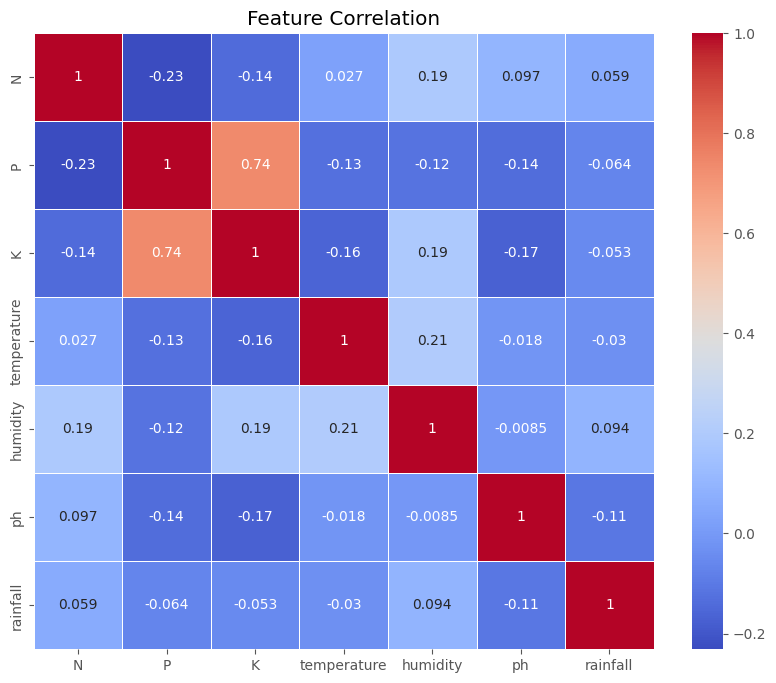

In [14]:
plt.figure(figsize=(10,8))

sns.heatmap(
    df.drop("label",axis=1).corr(),
    annot=True,
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Feature Correlation")

plt.show()

**9.8 Pairplot**

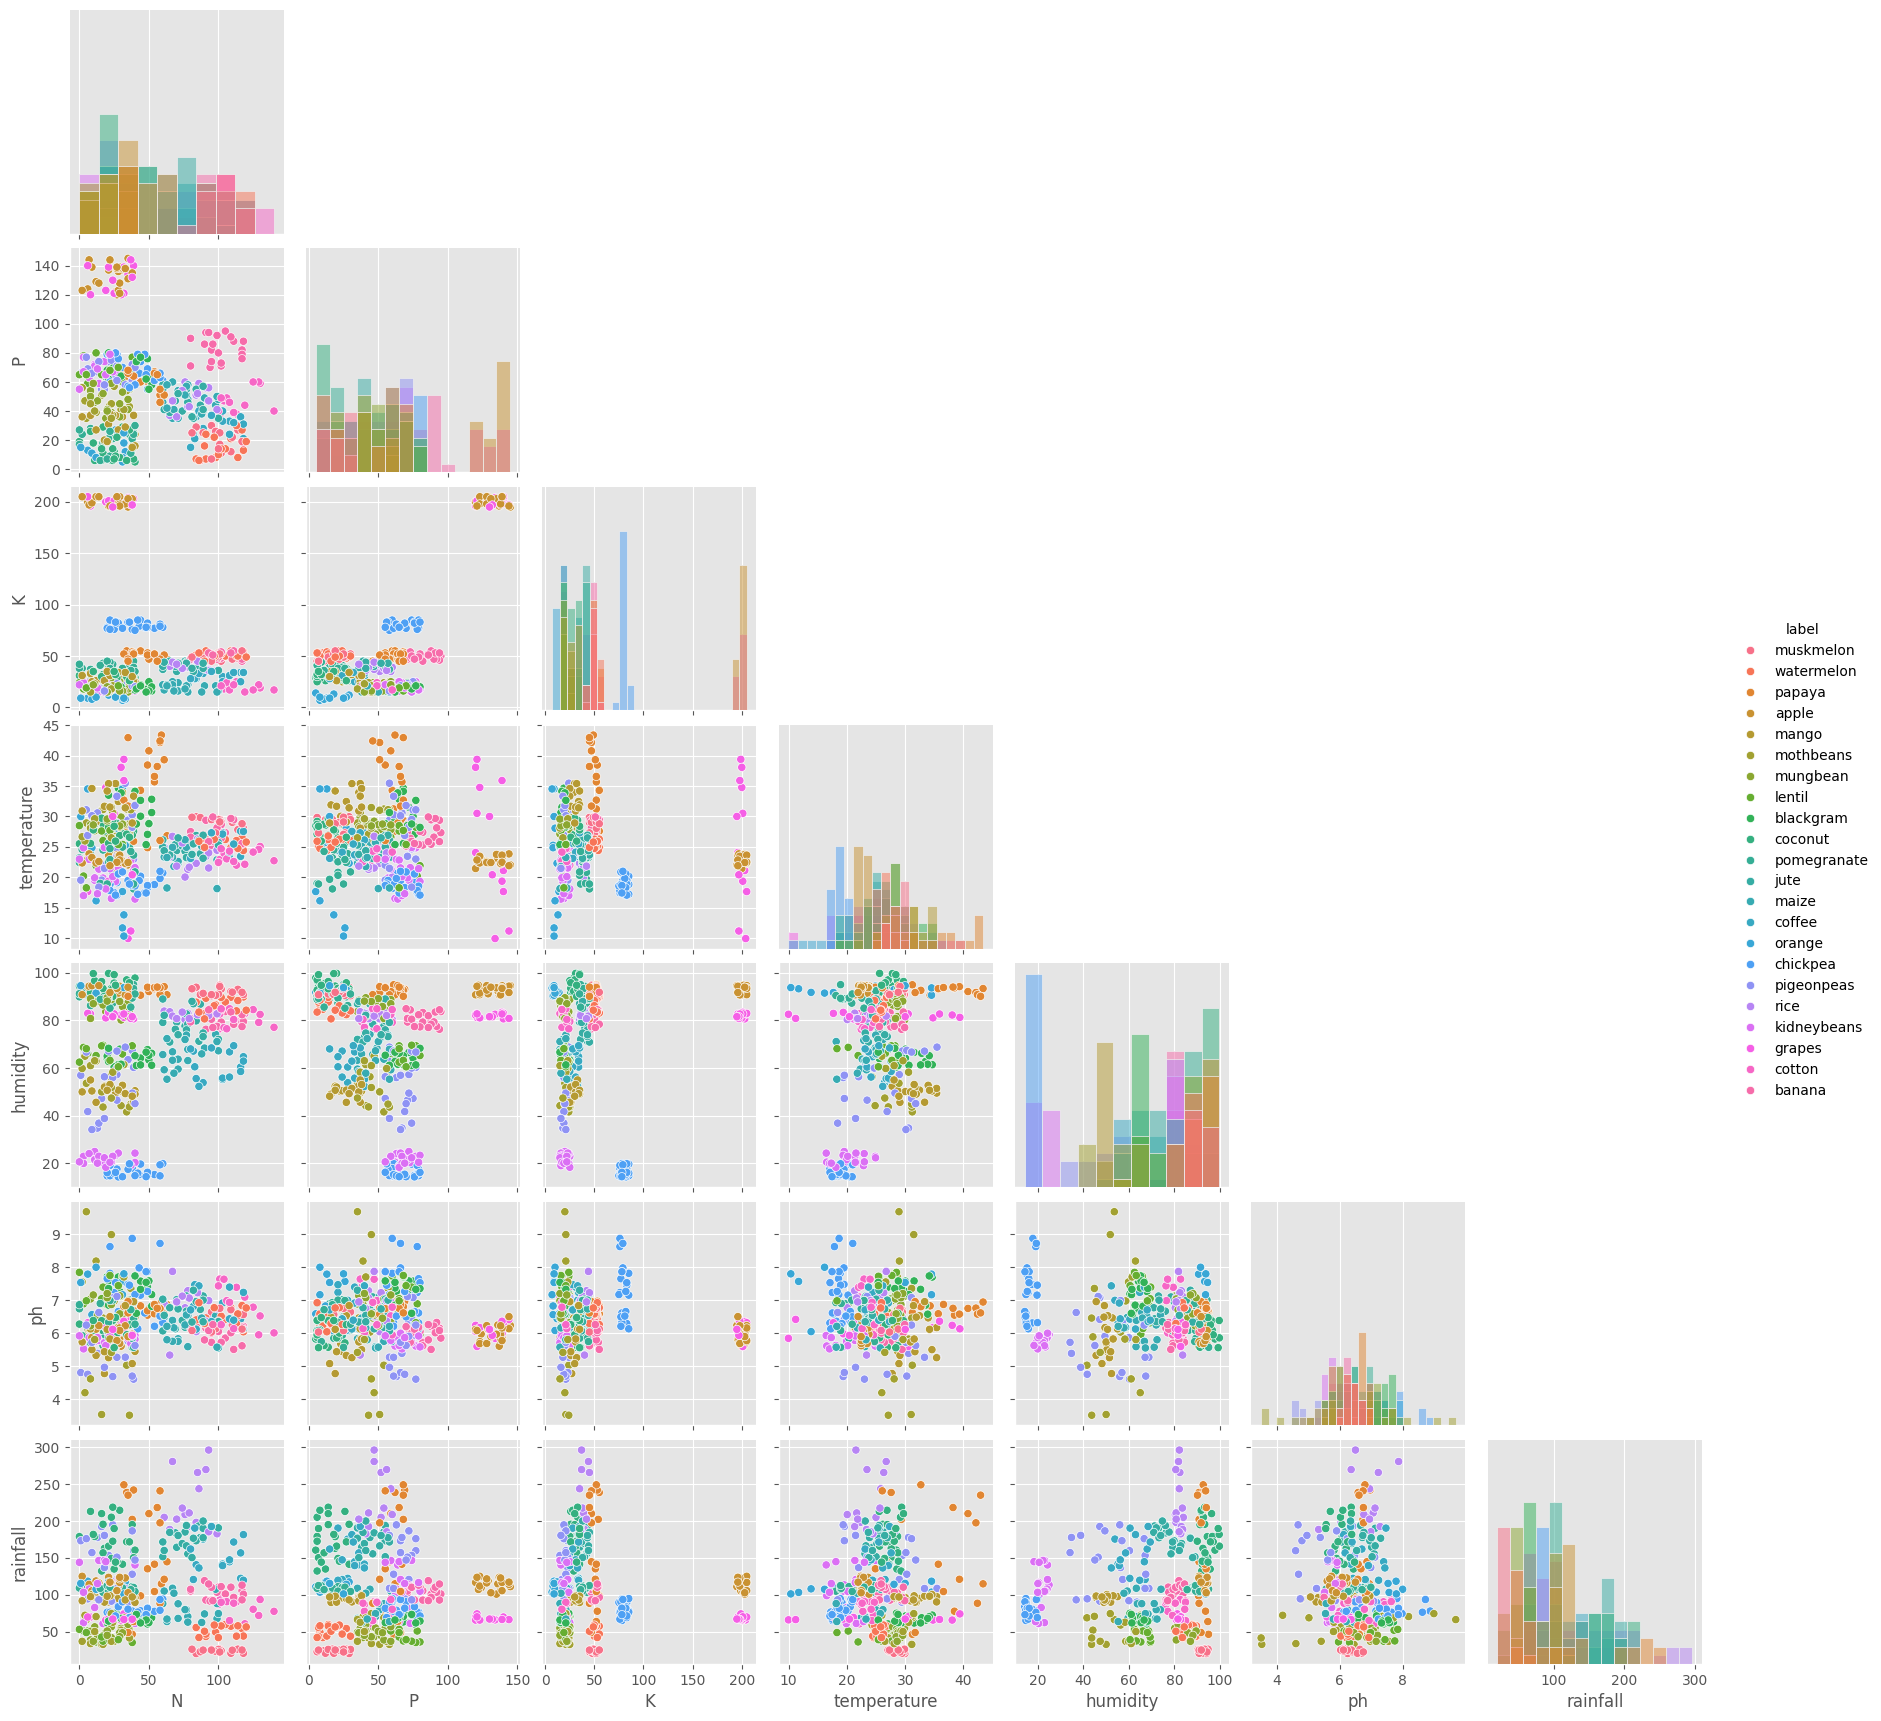

In [15]:
sample = df.sample(400, random_state=42)

sns.pairplot(
    sample,
    hue="label",
    corner=True,
    diag_kind="hist"
)

plt.show()

**9.9 Violin plots**

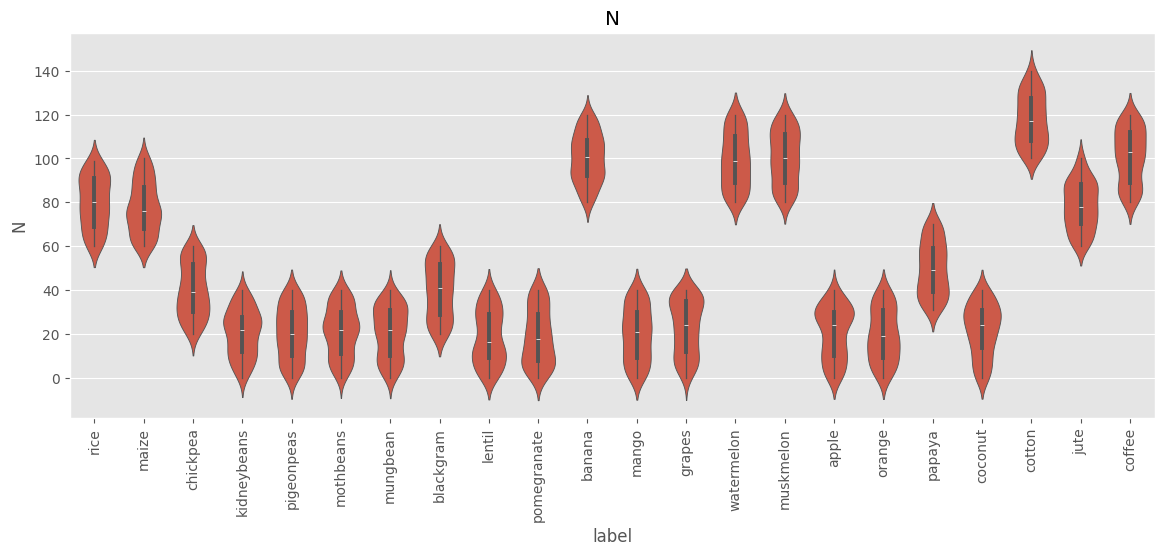

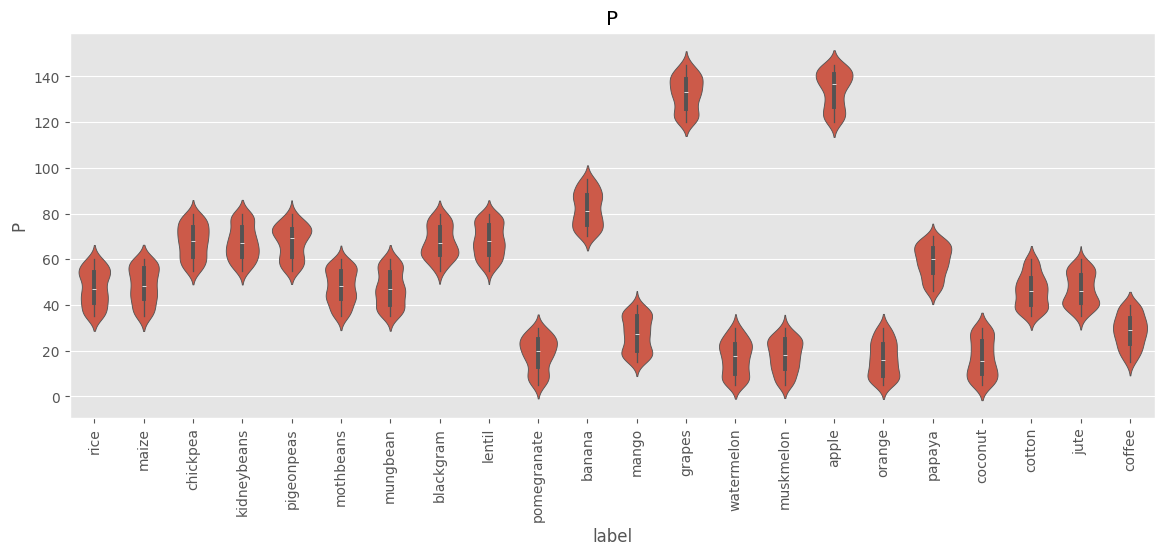

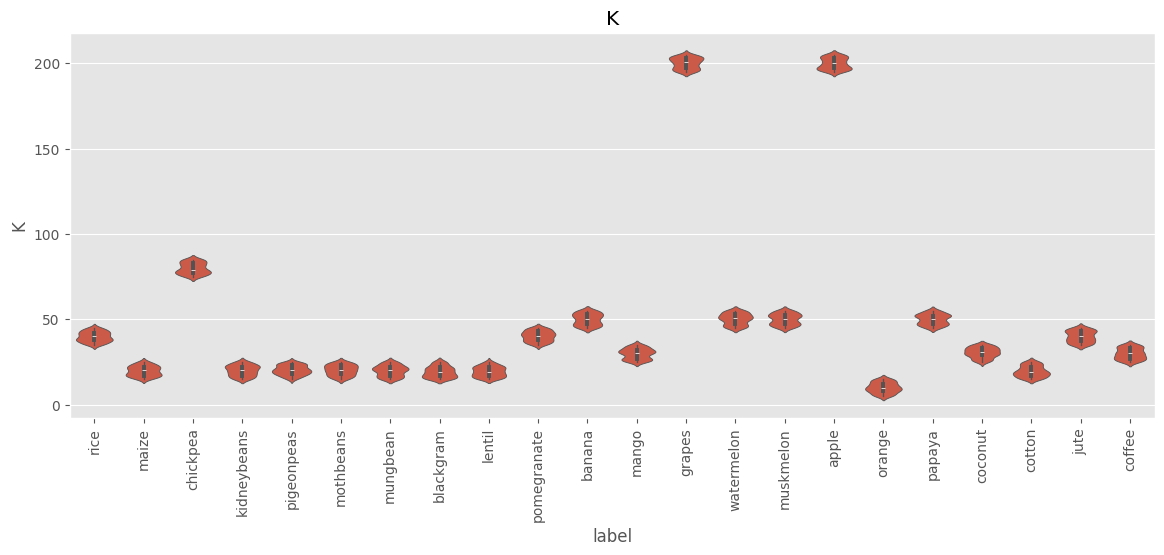

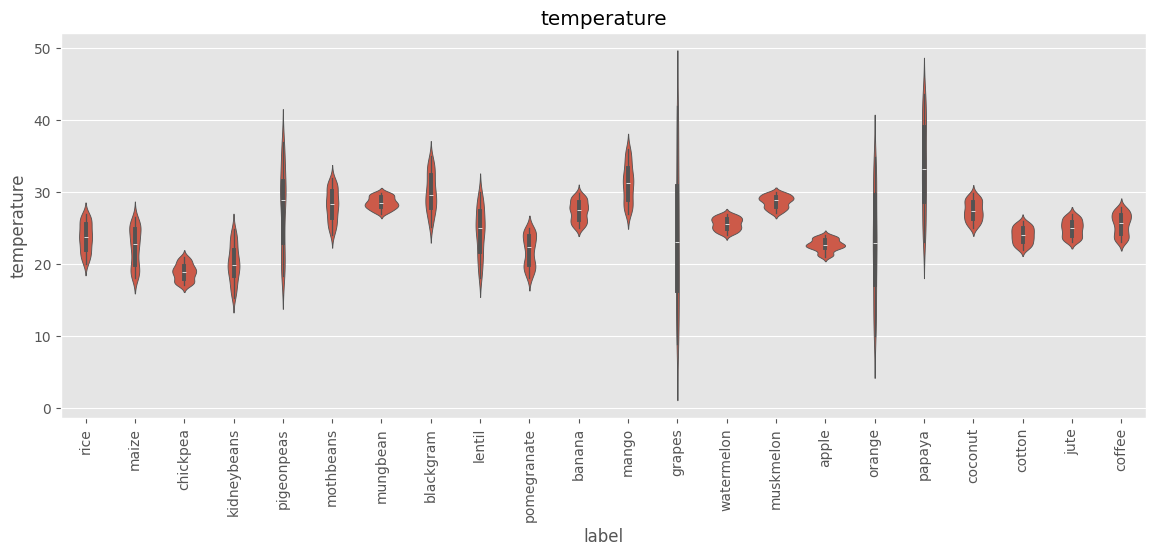

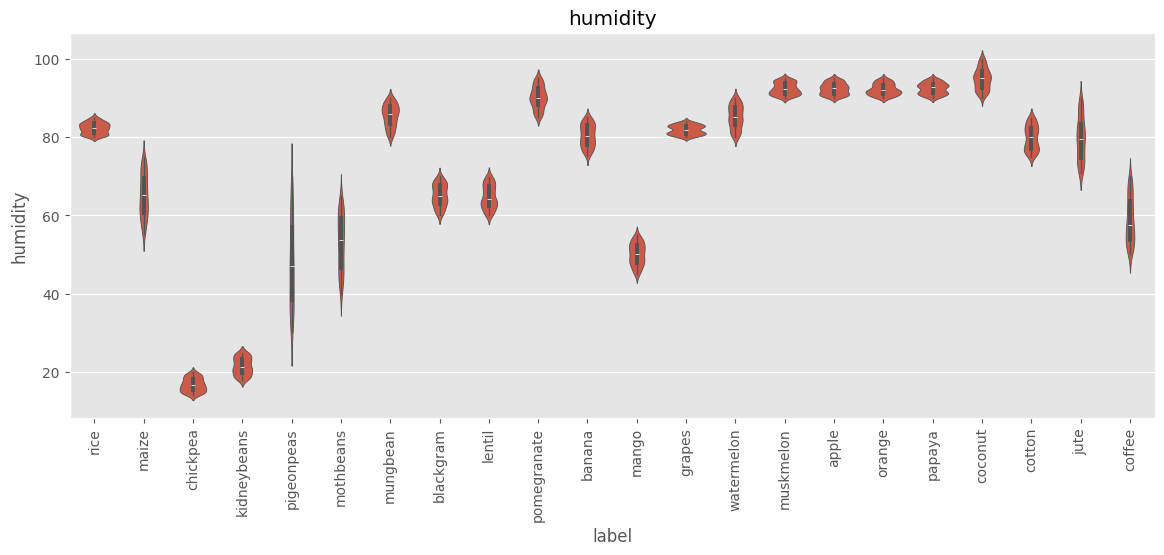

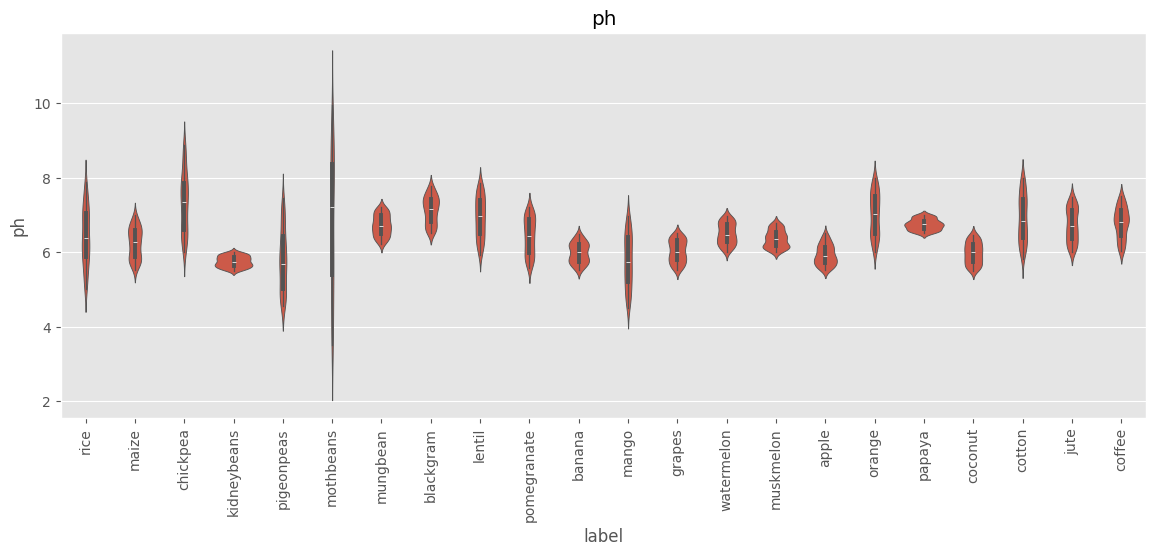

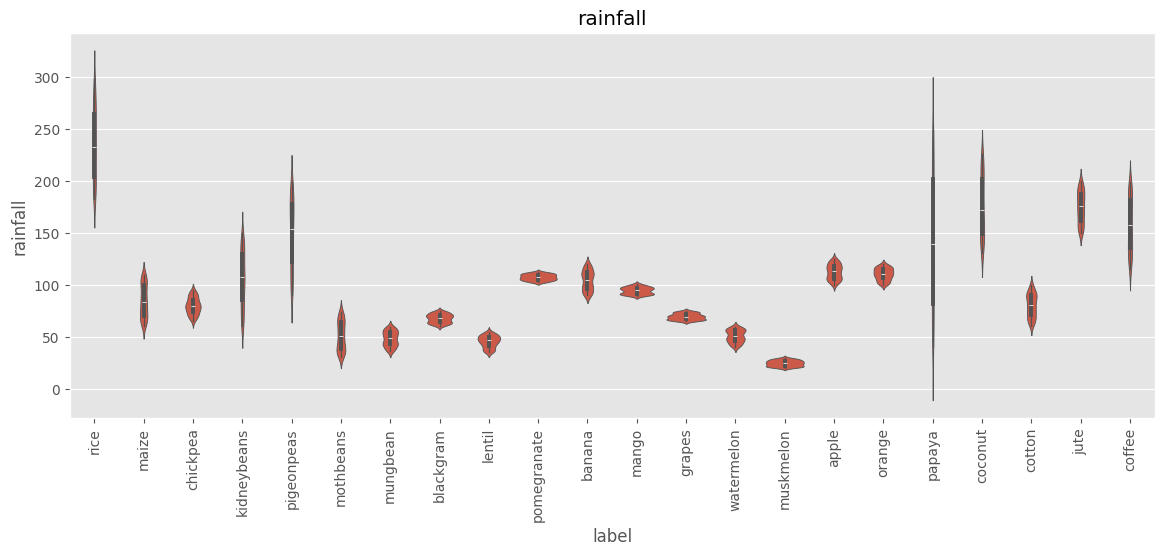

In [16]:
features = df.columns[:-1]

for feature in features:

    plt.figure(figsize=(14,5))

    sns.violinplot(
        data=df,
        x="label",
        y=feature
    )

    plt.xticks(rotation=90)

    plt.title(feature)

    plt.show()

**9.10 Feature Means by Crop**

In [17]:
crop_mean = df.groupby("label").mean()

display(
    crop_mean.style
    .background_gradient(cmap="Greens")
)

,N,P,K,temperature,humidity,ph,rainfall
label,,,,,,,
apple,20.800000,134.220000,199.890000,22.630942,92.333383,5.929663,112.654779
banana,100.230000,82.010000,50.050000,27.376798,80.358123,5.983893,104.626980
blackgram,40.020000,67.470000,19.240000,29.973340,65.118426,7.133952,67.884151
chickpea,40.090000,67.790000,79.920000,18.872847,16.860439,7.336957,80.058977
coconut,21.980000,16.930000,30.590000,27.409892,94.844272,5.976562,175.686646
coffee,101.200000,28.740000,29.940000,25.540477,58.869846,6.790308,158.066295
cotton,117.770000,46.240000,19.560000,23.988958,79.843474,6.912675,80.398043
grapes,23.180000,132.530000,200.110000,23.849575,81.875228,6.025937,69.611829
jute,78.400000,46.860000,39.990000,24.958376,79.639864,6.732778,174.792798


**9.11 Feature Variance**

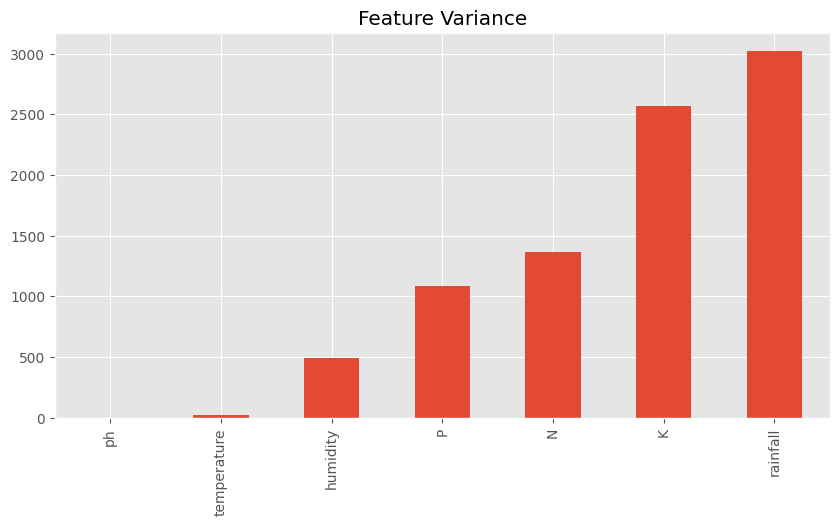

In [18]:
variance = df.drop("label",axis=1).var()

variance.sort_values().plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Feature Variance")

plt.show()

**9.12 Missing values heatmaps**

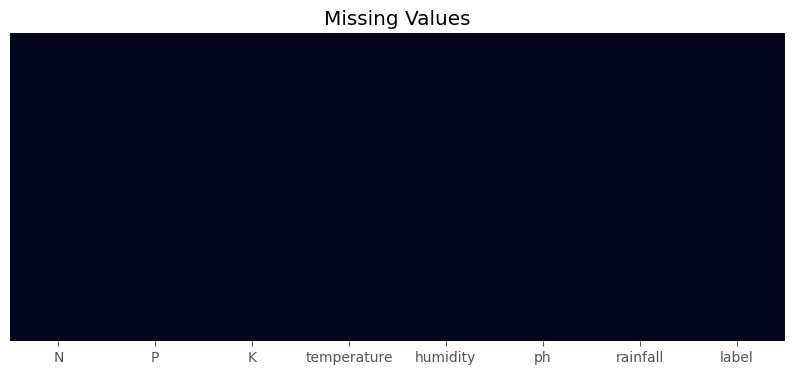

In [19]:
plt.figure(figsize=(10,4))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values")

plt.show()

**9.13 Duplicate check**

In [20]:
duplicates = df.duplicated()

print("Duplicate Rows:", duplicates.sum())

if duplicates.sum() > 0:
    display(df[duplicates])

Duplicate Rows: 0


# Section 10 — Data Preprocessing

**10.1 Define Features and Target**

In [21]:
X = df.drop(columns=["label"])
y = df["label"]

print("Features Shape :", X.shape)
print("Target Shape   :", y.shape)

display(X.head())
display(y.head())

Features Shape : (2200, 7)
Target Shape   : (2200,)


,N,P,K,temperature,humidity,ph,rainfall
0,90,42,43,20.879744,82.002744,6.502985,202.935536
1,85,58,41,21.770462,80.319644,7.038096,226.655537
2,60,55,44,23.004459,82.320763,7.840207,263.964248
3,74,35,40,26.491096,80.158363,6.980401,242.864034
4,78,42,42,20.130175,81.604873,7.628473,262.717340


0    rice
1    rice
2    rice
3    rice
4    rice
Name: label, dtype: object

**10.2 Label Encoding**

In [22]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Total Classes :", len(label_encoder.classes_))

print("\nCrop Classes\n")
for i, crop in enumerate(label_encoder.classes_):
    print(f"{i:2d} --> {crop}")

Total Classes : 22

Crop Classes

 0 --> apple
 1 --> banana
 2 --> blackgram
 3 --> chickpea
 4 --> coconut
 5 --> coffee
 6 --> cotton
 7 --> grapes
 8 --> jute
 9 --> kidneybeans
10 --> lentil
11 --> maize
12 --> mango
13 --> mothbeans
14 --> mungbean
15 --> muskmelon
16 --> orange
17 --> papaya
18 --> pigeonpeas
19 --> pomegranate
20 --> rice
21 --> watermelon


**10.3 Save Label Encoder**

In [23]:
joblib.dump(
    label_encoder,
    "label_encoder.pkl"
)

print("Label Encoder Saved")

Label Encoder Saved


**10.4 Train-Test Split**

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training Samples :", X_train.shape)
print("Testing Samples  :", X_test.shape)

Training Samples : (1760, 7)
Testing Samples  : (440, 7)


**10.5 Verify Class Distribution**

In [25]:
train_distribution = pd.Series(y_train).value_counts().sort_index()

test_distribution = pd.Series(y_test).value_counts().sort_index()

distribution = pd.DataFrame({
    "Train": train_distribution,
    "Test": test_distribution
})

display(distribution)

,Train,Test
0,80,20
1,80,20
2,80,20
3,80,20
4,80,20
5,80,20
6,80,20
7,80,20
8,80,20
9,80,20


**10.6 Feature Scaling**

In [26]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaling Completed")

Scaling Completed


**10.7 Save Scaler**

In [27]:
joblib.dump(
    scaler,
    "standard_scaler.pkl"
)

print("Scaler Saved")

Scaler Saved


**10.8 Convert Back to DataFrame**

In [28]:
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X.columns
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X.columns
)

display(X_train_scaled.head())

,N,P,K,temperature,humidity,ph,rainfall
0,-1.371628,-1.072910,-0.673510,0.819481,0.924395,0.937545,0.199440
1,-1.127411,2.084513,3.015261,0.783251,0.426613,-1.153846,-0.643677
2,-1.073140,0.536162,-0.476250,-0.879968,-2.186291,-1.107452,0.694001
3,-0.340487,-0.465713,-0.594606,0.138043,-0.459237,-0.229482,-1.231744
4,-0.883193,-1.255069,-0.791866,-2.563232,0.915842,-0.341959,0.289941


**10.9 Cross Validation Strategy**

In [29]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print(cv)

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


**10.10 Preprocessing Summary**

In [30]:
print("="*60)
print("PREPROCESSING SUMMARY")
print("="*60)

print(f"Training Samples : {len(X_train)}")
print(f"Testing Samples  : {len(X_test)}")

print(f"Features         : {X.shape[1]}")
print(f"Classes          : {len(label_encoder.classes_)}")

print("Scaling          : StandardScaler")

print("Cross Validation : 5 Fold Stratified")

PREPROCESSING SUMMARY
Training Samples : 1760
Testing Samples  : 440
Features         : 7
Classes          : 22
Scaling          : StandardScaler
Cross Validation : 5 Fold Stratified


**10.11 Save Feature Names**

In [31]:
feature_names = list(X.columns)

joblib.dump(
    feature_names,
    "feature_names.pkl"
)

feature_names

['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

# Section 11 — Model Building & Benchmarking

**11.1 Create Model Dictionary**

In [32]:
models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(),

    "SVM": SVC(
        probability=True,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        random_state=42,
        eval_metric="mlogloss"
    ),

    "LightGBM": LGBMClassifier(
        random_state=42
    ),

    "CatBoost": CatBoostClassifier(
        verbose=0,
        random_state=42
    )
}

**11.2 Create Results DataFrame**

In [33]:
results = pd.DataFrame(
    columns=[
        "Model",
        "Train Accuracy",
        "Test Accuracy",
        "CV Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "Training Time",
        "Prediction Time"
    ]
)

**11.3 Benchmark All Models**

In [34]:
import time

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

for name, model in models.items():

    print("="*60)
    print(name)
    print("="*60)

    if name in ["Logistic Regression","KNN","SVM"]:

        Xtr = X_train_scaled
        Xts = X_test_scaled

    else:

        Xtr = X_train
        Xts = X_test

    start_train = time.time()

    model.fit(Xtr, y_train)

    end_train = time.time()

    start_pred = time.time()

    predictions = model.predict(Xts)

    end_pred = time.time()

    train_accuracy = model.score(Xtr, y_train)

    test_accuracy = accuracy_score(
        y_test,
        predictions
    )

    cv_score = cross_val_score(
        model,
        Xtr,
        y_train,
        cv=cv,
        scoring="accuracy"
    ).mean()

    precision = precision_score(
        y_test,
        predictions,
        average="macro"
    )

    recall = recall_score(
        y_test,
        predictions,
        average="macro"
    )

    f1 = f1_score(
        y_test,
        predictions,
        average="macro"
    )

    results.loc[len(results)] = [

        name,

        train_accuracy,

        test_accuracy,

        cv_score,

        precision,

        recall,

        f1,

        end_train-start_train,

        end_pred-start_pred
    ]

print("Benchmark Completed")

Logistic Regression
Decision Tree
Random Forest
KNN
SVM
XGBoost
LightGBM
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001369 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1331
[LightGBM] [Info] Number of data points in the train set: 1760, number of used features: 7
[LightGBM] [Info] Start training from score -3.091042
[LightGBM] [Info] Start training from score -3.091042
[LightGBM] [Info] Start training from score -3.091042
[LightGBM] [Info] Start training from score -3.091042
[LightGBM] [Info] Start training from score -3.091042
[LightGBM] [Info] Start training from score -3.091042
[LightGBM] [Info] Start training from score -3.091042
[LightGBM] [Info] Start training from score -3.091042
[LightGBM] [Info] Start training from score -3.091042
[LightGBM] [Info] Start training from score -3.091042
[LightGBM] [Info] Start training from score -3.091042
[LightGBM] [Info] Start training from score -3

**11.4 Display Results**

In [35]:
results = results.sort_values(
    by="Test Accuracy",
    ascending=False
)

display(
    results.style
    .background_gradient(cmap="Greens")
)

,Model,Train Accuracy,Test Accuracy,CV Accuracy,Precision,Recall,F1 Score,Training Time,Prediction Time
7,CatBoost,1.000000,0.997727,0.987500,0.997835,0.997727,0.997726,16.645994,0.007226
2,Random Forest,1.000000,0.995455,0.994318,0.995671,0.995455,0.995452,0.750776,0.021705
5,XGBoost,1.000000,0.993182,0.991477,0.993506,0.993182,0.993116,0.991463,0.008438
6,LightGBM,1.000000,0.988636,0.991477,0.989374,0.988636,0.988559,1.006995,0.031116
4,SVM,0.985795,0.984091,0.979545,0.985610,0.984091,0.984038,0.222691,0.030235
1,Decision Tree,1.000000,0.979545,0.985227,0.980598,0.979545,0.979423,0.018649,0.001203
3,KNN,0.984659,0.979545,0.965341,0.980356,0.979545,0.979283,0.006705,0.006506
0,Logistic Regression,0.973864,0.972727,0.968182,0.974022,0.972727,0.972464,0.090188,0.001559


**11.5 Visual Comparison**

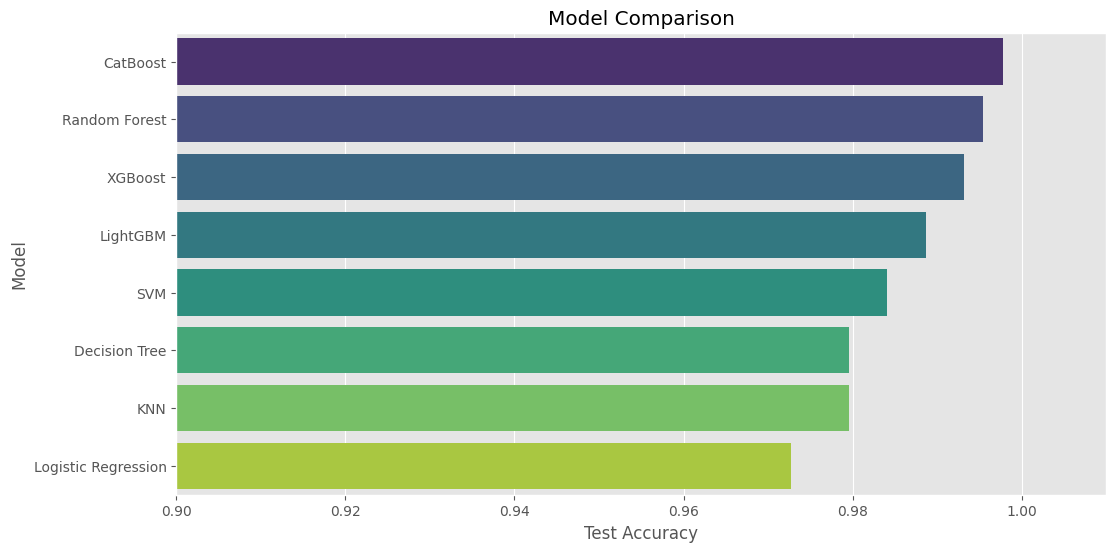

In [36]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=results,
    x="Test Accuracy",
    y="Model",
    palette="viridis"
)

plt.xlim(0.90,1.01)

plt.title("Model Comparison")

plt.show()

**11.6 Cross Validation Comparison**

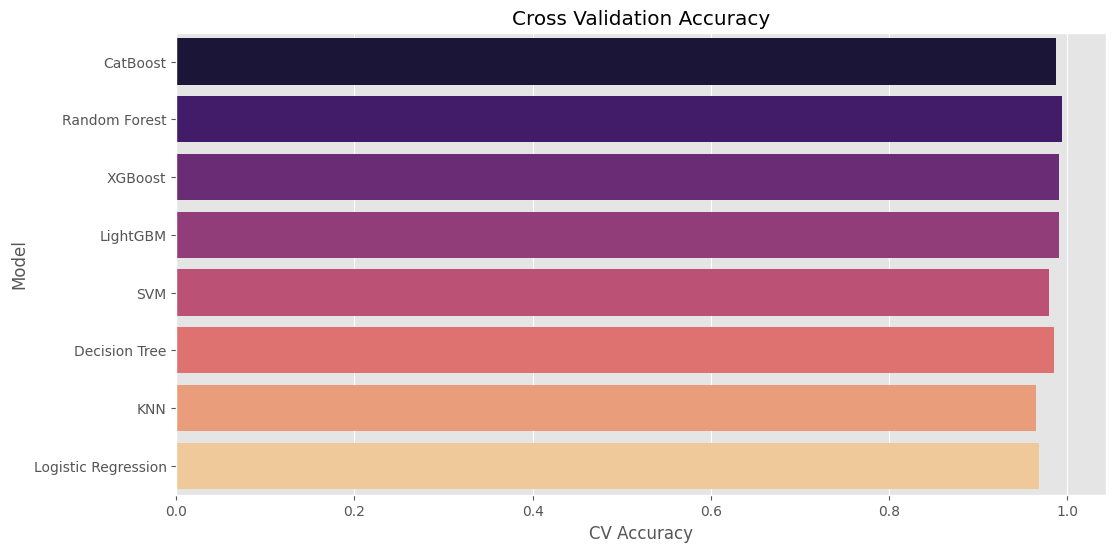

In [37]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=results,
    x="CV Accuracy",
    y="Model",
    palette="magma"
)

plt.title("Cross Validation Accuracy")

plt.show()

**11.7 F1 Score Comparison**

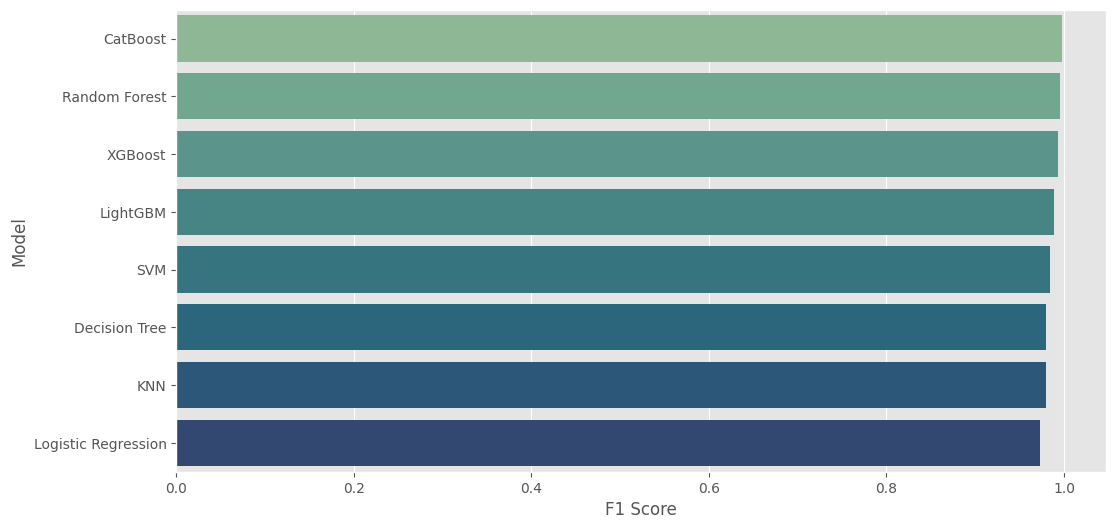

In [38]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=results,
    x="F1 Score",
    y="Model",
    palette="crest"
)

plt.show()

**11.8 Training Time Comparison**

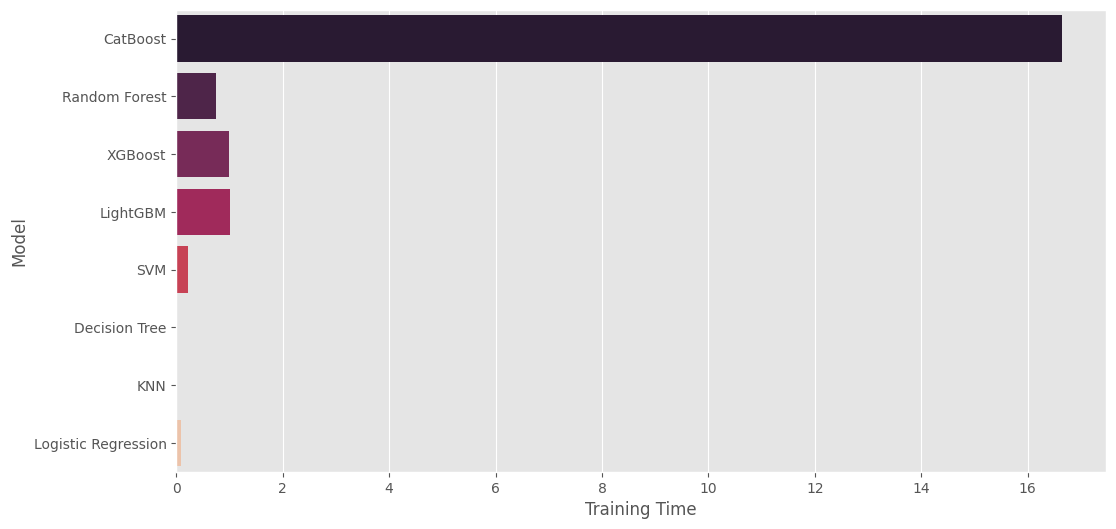

In [39]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=results,
    x="Training Time",
    y="Model",
    palette="rocket"
)

plt.show()

**11.9 Prediction Time Comparison**

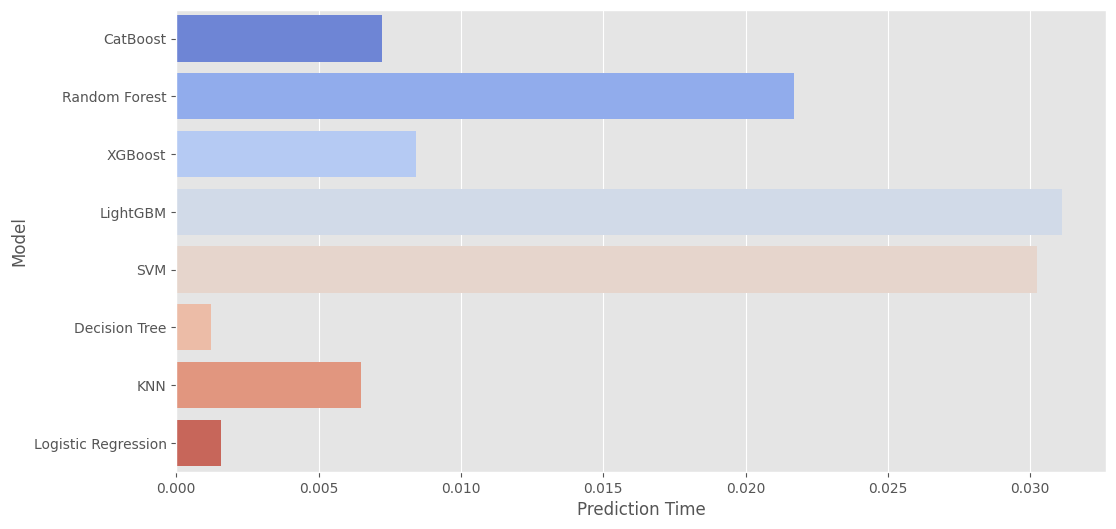

In [40]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=results,
    x="Prediction Time",
    y="Model",
    palette="coolwarm"
)

plt.show()

**11.10 Best Model**

In [41]:
best_model_name = results.iloc[0]["Model"]

print("="*60)
print("BEST MODEL")
print("="*60)

print(best_model_name)

BEST MODEL
CatBoost


**11.11 Load Best Model**

In [42]:
best_model = models[best_model_name]

print(best_model)

CatBoostClassifier(random_state=42, verbose=0)


**11.12 Model Summary**

In [43]:
display(results)

,Model,Train Accuracy,Test Accuracy,CV Accuracy,Precision,Recall,F1 Score,Training Time,Prediction Time
7,CatBoost,1.000000,0.997727,0.987500,0.997835,0.997727,0.997726,16.645994,0.007226
2,Random Forest,1.000000,0.995455,0.994318,0.995671,0.995455,0.995452,0.750776,0.021705
5,XGBoost,1.000000,0.993182,0.991477,0.993506,0.993182,0.993116,0.991463,0.008438
6,LightGBM,1.000000,0.988636,0.991477,0.989374,0.988636,0.988559,1.006995,0.031116
4,SVM,0.985795,0.984091,0.979545,0.985610,0.984091,0.984038,0.222691,0.030235
1,Decision Tree,1.000000,0.979545,0.985227,0.980598,0.979545,0.979423,0.018649,0.001203
3,KNN,0.984659,0.979545,0.965341,0.980356,0.979545,0.979283,0.006705,0.006506
0,Logistic Regression,0.973864,0.972727,0.968182,0.974022,0.972727,0.972464,0.090188,0.001559


# **Section 12 — Hyperparameter Tuning**

**12.1 Select Best Model**

In [44]:
best_model_name = results.iloc[0]["Model"]

print(f"Best Model : {best_model_name}")

Best Model : CatBoost


**12.2 Hyperparameter Grids**

In [45]:
param_grids = {

    "Random Forest": {

        "n_estimators": [100,200,300],

        "max_depth": [None,10,20,30],

        "min_samples_split": [2,5,10],

        "min_samples_leaf": [1,2,4]

    },

    "XGBoost": {

        "n_estimators":[100,200],

        "max_depth":[4,6,8],

        "learning_rate":[0.01,0.05,0.1],

        "subsample":[0.8,1.0]

    },

    "LightGBM": {

        "n_estimators":[100,200],

        "learning_rate":[0.01,0.05,0.1],

        "num_leaves":[31,50,80]

    },

    "CatBoost": {

        "depth":[4,6,8],

        "iterations":[200,500],

        "learning_rate":[0.03,0.05,0.1]

    }

}

**12.3 Grid Search**

In [46]:
if best_model_name in param_grids:

    print("Running Grid Search...")

    grid = GridSearchCV(

        estimator=models[best_model_name],

        param_grid=param_grids[best_model_name],

        scoring="accuracy",

        cv=5,

        n_jobs=-1,

        verbose=2

    )

    if best_model_name in ["Logistic Regression","SVM","KNN"]:

        grid.fit(X_train_scaled,y_train)

    else:

        grid.fit(X_train,y_train)

    best_model = grid.best_estimator_

    print("\nBest Parameters")

    print(grid.best_params_)

else:

    best_model = models[best_model_name]

    print("No tuning defined.")

Running Grid Search...
Fitting 5 folds for each of 18 candidates, totalling 90 fits

Best Parameters
{'depth': 4, 'iterations': 500, 'learning_rate': 0.1}


**12.4 Evaluate Tuned Model**

In [47]:
if best_model_name in ["Logistic Regression","SVM","KNN"]:

    predictions = best_model.predict(X_test_scaled)

else:

    predictions = best_model.predict(X_test)

accuracy = accuracy_score(
    y_test,
    predictions
)

print(f"Final Accuracy : {accuracy:.4f}")

Final Accuracy : 0.9955


**12.5 Classification Report**

In [48]:
print(classification_report(

    y_test,

    predictions,

    target_names=label_encoder.classes_

))

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       0.95      1.00      0.98        20
      lentil       1.00      1.00      1.00        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

**12.6 Confusion Matrix**

<Figure size 1500x1500 with 0 Axes>

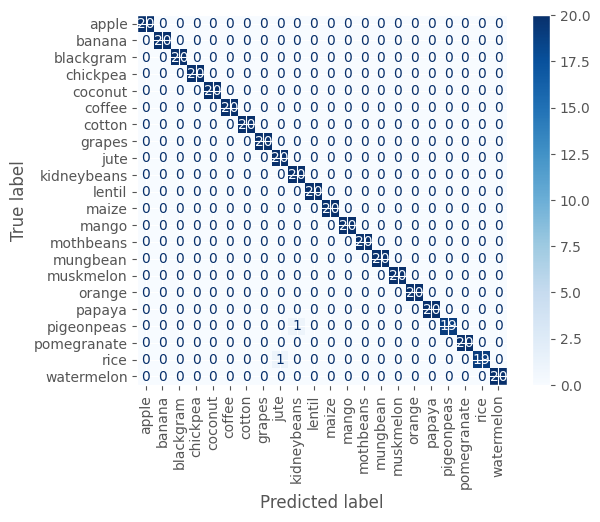

In [49]:
plt.figure(figsize=(15,15))

cm = confusion_matrix(
    y_test,
    predictions
)

disp = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=label_encoder.classes_

)

disp.plot(
    cmap="Blues",
    xticks_rotation=90
)

plt.show()

**12.7 Cross Validation of Final Model**

In [50]:
if best_model_name in ["Logistic Regression","SVM","KNN"]:

    score = cross_val_score(

        best_model,

        X_train_scaled,

        y_train,

        cv=5,

        scoring="accuracy"

    )

else:

    score = cross_val_score(

        best_model,

        X_train,

        y_train,

        cv=5,

        scoring="accuracy"

    )

print(score)

print(f"Mean CV Accuracy : {score.mean():.4f}")

print(f"Std Deviation    : {score.std():.4f}")

[0.99715909 0.98579545 0.99715909 1.         0.98295455]
Mean CV Accuracy : 0.9926
Std Deviation    : 0.0069


# Section 13 — Feature Importance

**13.1 Feature Importance**

In [51]:
if hasattr(best_model,"feature_importances_"):

    importance = pd.DataFrame({

        "Feature":X.columns,

        "Importance":best_model.feature_importances_

    })

    importance = importance.sort_values(

        by="Importance",

        ascending=False

    )

    display(importance)

else:

    print("Feature Importance Not Available")

,Feature,Importance
2,K,22.450703
4,humidity,20.431141
1,P,18.439144
0,N,15.844292
6,rainfall,15.624019
3,temperature,5.091615
5,ph,2.119086


**13.3 Plot Importance**

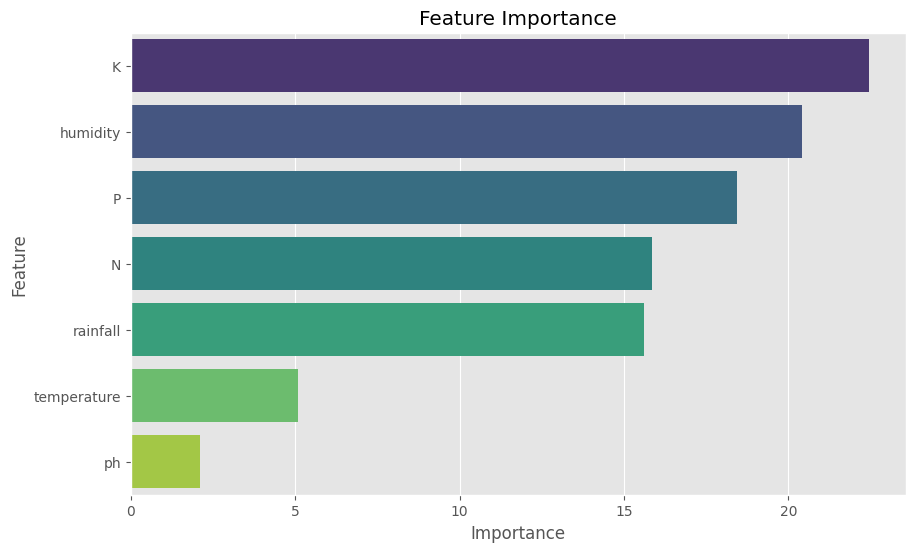

In [52]:
if hasattr(best_model,"feature_importances_"):

    plt.figure(figsize=(10,6))

    sns.barplot(

        data=importance,

        x="Importance",

        y="Feature",

        palette="viridis"

    )

    plt.title("Feature Importance")

    plt.show()

**Section 14 — Save Model**

In [53]:
joblib.dump(

    best_model,

    "crop_recommendation_model.pkl"

)

print("Model Saved")

Model Saved


In [54]:
joblib.dump(

    scaler,

    "standard_scaler.pkl"

)

joblib.dump(

    label_encoder,

    "label_encoder.pkl"

)

joblib.dump(

    feature_names,

    "feature_names.pkl"

)

print("Artifacts Saved")

Artifacts Saved


**Prediction Function**

In [55]:
def recommend_crop(

    nitrogen,

    phosphorus,

    potassium,

    temperature,

    humidity,

    ph,

    rainfall,

    top_n=3

):

    sample = pd.DataFrame({

        "N":[nitrogen],

        "P":[phosphorus],

        "K":[potassium],

        "temperature":[temperature],

        "humidity":[humidity],

        "ph":[ph],

        "rainfall":[rainfall]

    })

    if best_model_name in ["Logistic Regression","KNN","SVM"]:

        sample = scaler.transform(sample)

    probabilities = best_model.predict_proba(sample)[0]

    indices = np.argsort(probabilities)[::-1][:top_n]

    recommendations = []

    for idx in indices:

        recommendations.append({

            "Crop":label_encoder.inverse_transform([idx])[0],

            "Confidence":round(probabilities[idx]*100,2)

        })

    return pd.DataFrame(recommendations)

In [56]:
test_cases = [
    [90,42,43,21.5,82.0,6.5,210],
    [78,48,20,25.2,65.5,6.0,85],
    [120,40,20,24.5,79.0,6.8,95],
    [78,46,39,23.1,83.0,6.3,176],
    [104,18,30,24.8,58.5,6.7,160],
    [105,38,52,27.8,81.0,6.4,105],
    [25,27,30,31.0,50.0,6.2,95],
    [22,16,31,28.5,93.0,5.8,195],
    [40,68,80,19.8,17.5,7.1,68],
    [24,135,200,22.5,92.0,5.9,112]
]

for i, values in enumerate(test_cases, start=1):
    print("=" * 60)
    print(f"Test Case {i}")
    print(recommend_crop(*values))

Test Case 1
     Crop  Confidence
0    rice       99.24
1    jute        0.66
2  papaya        0.03
Test Case 2
        Crop  Confidence
0      maize       99.56
1     cotton        0.13
2  mothbeans        0.10
Test Case 3
     Crop  Confidence
0  cotton       98.84
1   maize        0.80
2  coffee        0.17
Test Case 4
          Crop  Confidence
0         jute       98.75
1         rice        0.95
2  pomegranate        0.06
Test Case 5
     Crop  Confidence
0  coffee       99.97
1   mango        0.01
2   maize        0.01
Test Case 6
         Crop  Confidence
0      banana       73.46
1        jute        8.70
2  watermelon        7.86
Test Case 7
        Crop  Confidence
0      mango       99.89
1  mothbeans        0.04
2     coffee        0.03
Test Case 8
      Crop  Confidence
0  coconut       99.85
1   papaya        0.04
2     rice        0.02
Test Case 9
          Crop  Confidence
0     chickpea       99.88
1  kidneybeans        0.06
2       grapes        0.02
Test Case 10
   

# **Save Outputs**

In [57]:
import os
import joblib

ROOT = "crop_recommendation_artifacts"

MODELS = os.path.join(ROOT, "models")
REPORTS = os.path.join(ROOT, "reports")
PLOTS = os.path.join(ROOT, "plots")

os.makedirs(MODELS, exist_ok=True)
os.makedirs(REPORTS, exist_ok=True)
os.makedirs(PLOTS, exist_ok=True)

print("Folders Created")



Folders Created


In [58]:
joblib.dump(best_model, os.path.join(MODELS, "crop_recommendation_model.pkl"))
joblib.dump(scaler, os.path.join(MODELS, "standard_scaler.pkl"))
joblib.dump(label_encoder, os.path.join(MODELS, "label_encoder.pkl"))
joblib.dump(feature_names, os.path.join(MODELS, "feature_names.pkl"))

print("Models Saved")

Models Saved


In [59]:
results.to_csv(
    os.path.join(REPORTS, "model_metrics.csv"),
    index=False
)

In [60]:
report = classification_report(
    y_test,
    predictions,
    target_names=label_encoder.classes_
)

with open(
    os.path.join(REPORTS, "classification_report.txt"),
    "w"
) as f:
    f.write(report)

print(report)

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       0.95      1.00      0.98        20
      lentil       1.00      1.00      1.00        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

In [61]:
prediction_df = pd.DataFrame({

    "Actual":
        label_encoder.inverse_transform(y_test),

    "Predicted":
        label_encoder.inverse_transform(predictions)

})

prediction_df.to_csv(
    os.path.join(REPORTS, "test_predictions.csv"),
    index=False
)

In [62]:
if hasattr(best_model, "feature_importances_"):

    importance.to_csv(
        os.path.join(REPORTS, "feature_importance.csv"),
        index=False
    )

In [63]:
with open(
    os.path.join(REPORTS, "model_information.txt"),
    "w"
) as f:

    f.write(f"Best Model : {best_model_name}\n")
    f.write(f"Accuracy   : {accuracy:.4f}\n")
    f.write(f"CV Mean    : {score.mean():.4f}\n")
    f.write(f"CV Std     : {score.std():.4f}\n")

In [64]:
plt.tight_layout()

plt.savefig(
    os.path.join(PLOTS, "feature_importance.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>

In [65]:
readme = """
YieldCraft AI

Crop Recommendation System

Contents

models/
    crop_recommendation_model.pkl
    standard_scaler.pkl
    label_encoder.pkl
    feature_names.pkl

reports/
    evaluation reports

plots/
    all generated graphs

The model is ready for FastAPI deployment.
"""

with open(
    os.path.join(ROOT, "README.txt"),
    "w"
) as f:
    f.write(readme)

In [66]:
import shutil

shutil.make_archive(
    "crop_recommendation_artifacts",
    "zip",
    ROOT
)

print("ZIP File Created Successfully")

ZIP File Created Successfully
